In [1]:
import pandas as pd

# Đọc file
df = pd.read_csv("FactAccident.csv")

# Xem qua dữ liệu
print(df.head())

           id  start_lat  start_lng  weather_conditions  fog  rain  snow  \
0  C-10152838   1.000348   1.235562                  88    0     0     0   
1  C-16760137  -0.607705   0.447920                   7    0     0     0   
2  C-23594835   0.683116   1.071714                   7    0     0     0   
3  C-24757814  -0.958212   0.105401                  14    0     0     0   
4  C-32022596  -0.625629  -1.489520                   7    0     0     0   

   hail  thunderstorm  tornado  severity  distance_mi  \
0     0             0        0  1.181436     0.545331   
1     0             0        0 -0.097353    -0.054897   
2     0             0        0 -0.097353    -0.325520   
3     0             0        0 -0.097353     0.992900   
4     0             0        0  2.460224    -1.036772   

   delayfromfreeflowspeed_mins  delayfromtypicaltraffic_mins  \
0                    -0.437970                     -0.694001   
1                     0.309673                      0.445622   
2       

In [2]:
import pandas as pd
import numpy as np

for col in ["starttime", "endtime"]:
    df[col] = pd.to_datetime(df[col], errors='coerce')  # tránh lỗi parse

    df[f"{col}_year"] = df[col].dt.year
    df[f"{col}_month"] = df[col].dt.month
    df[f"{col}_day"] = df[col].dt.day
    df[f"{col}_hour"] = df[col].dt.hour
    df[f"{col}_minute"] = df[col].dt.minute
    df[f"{col}_second"] = df[col].dt.second

df = df.drop(columns=["starttime", "endtime"], errors='ignore')

df = df.drop(columns=["id"])




In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['congestion_speed'])
y = df['congestion_speed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import WeightedRandomSampler
from sklearn.metrics import f1_score
import numpy as np
from itertools import product
import json
import time

torch.set_num_threads(20)

class DynamicMLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_dims, dropout_rate):
        super(DynamicMLP, self).__init__()
        layers = []
        prev_dim = input_dim

        for i, hidden_dim in enumerate(hidden_dims):
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.SiLU(),
                nn.Dropout(dropout_rate)
            ])
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_model(params, X_train_t, y_train_t, X_val_t, y_val_t, input_dim, num_classes):
    device = torch.device("cpu")

    model = DynamicMLP(input_dim, num_classes, params['hidden_dims'], params['dropout'])
    model.to(device)

    class_counts = np.bincount(y_train_t.numpy())
    weights = 1. / class_counts
    sample_weights = [weights[y] for y in y_train_t.numpy()]
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

    train_loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=params['batch_size'],
        sampler=sampler
    )
    val_loader = DataLoader(
        TensorDataset(X_val_t, y_val_t),
        batch_size=params['batch_size'],
        shuffle=False
    )

    classes = np.unique(y_train_t.numpy())
    weights_tensor = compute_class_weight('balanced', classes=classes, y=y_train_t.numpy())
    weights_tensor = torch.tensor(weights_tensor, dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights_tensor)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=params['lr'],
        weight_decay=params['weight_decay']
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

    epochs = 50
    best_f1 = 0
    best_model_state = None
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

    patience = 7
    patience_counter = 0
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        model.eval()
        y_true, y_pred = [], []
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                val_loss += criterion(outputs, y_batch).item()
                _, predicted = torch.max(outputs, 1)
                y_true.extend(y_batch.cpu().numpy())
                y_pred.extend(predicted.cpu().numpy())

        val_acc = np.mean(np.array(y_true) == np.array(y_pred))
        f1 = f1_score(y_true, y_pred, average='macro')
        val_loss /= len(val_loader)

        history['train_loss'].append(running_loss/len(train_loader))
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(f1)

        print(f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {running_loss/len(train_loader):.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | F1 macro: {f1:.4f}")

        scheduler.step(f1)

        if f1 > best_f1:
            best_f1 = f1
            best_model_state = model.state_dict().copy()
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch+1}. Best F1: {best_f1:.4f} at epoch {best_epoch+1}")
            break

    if patience_counter < patience:
        print(f"Training completed. Best F1: {best_f1:.4f} at epoch {best_epoch+1}")

    return best_f1, history, best_model_state

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)
X_val_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_test.values, dtype=torch.long)

input_dim = X_train.shape[1]
print(f"Input dimension: {input_dim}")
num_classes = len(np.unique(y_train))
print(f"Số lớp: {num_classes}")

# Định nghĩa param grid
param_grid = {
    'hidden_dims': [
        [1024, 512, 256, 128]
    ],
    'dropout': [0.1], 
    'lr': [0.001],
    'weight_decay': [1e-4],
    'batch_size': [1024]
}

keys = param_grid.keys()
values = param_grid.values()
all_combinations = [dict(zip(keys, combination)) for combination in product(*values)]

print(f"Bắt đầu grid search với {len(all_combinations)} tổ hợp tham số...")

results = []
best_f1_overall = 0
best_params_overall = None
best_model_overall = None

for i, params in enumerate(all_combinations):
    print(f"\n=== Thử tổ hợp {i+1}/{len(all_combinations)} ===")
    print(f"Tham số: {params}")
    start_time = time.time()

    try:
        best_f1, history, best_model_state = train_model(
            params, X_train_t, y_train_t, X_val_t, y_val_t, input_dim, num_classes,
        )

        end_time = time.time()
        training_time = end_time - start_time

        result = {
            'params': params,
            'best_f1': best_f1,
            'training_time': training_time,
            'final_val_acc': history['val_acc'][-1],
            'final_val_loss': history['val_loss'][-1]
        }
        results.append(result)

        print(f"Kết quả: F1 = {best_f1:.4f}, Time = {training_time:.2f}s")


        if best_f1 > best_f1_overall:
            best_f1_overall = best_f1
            best_params_overall = params
            best_model_overall = best_model_state
            print("*** New best model! ***")

    except Exception as e:
        print(f"Lỗi với tham số {params}: {e}")
        continue


print("KẾT QUẢ TỐT NHẤT:")
print(f"F1 Score: {best_f1_overall:.4f}")
print(f"Tham số: {best_params_overall}")


if best_model_overall is not None:
    torch.save(best_model_overall, "best_mlp.pth")
    print("Đã lưu model tốt nhất!")



Input dimension: 28
Số lớp: 3
Bắt đầu grid search với 8 tổ hợp tham số...

=== Thử tổ hợp 1/8 ===
Tham số: {'hidden_dims': [512, 256, 128], 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 1024}
Epoch [1/50] Train Loss: 1.1458 | Val Loss: 1.0922 | Val Acc: 0.2200 | F1 macro: 0.1460
Epoch [2/50] Train Loss: 1.0105 | Val Loss: 1.0853 | Val Acc: 0.3050 | F1 macro: 0.2804
Epoch [3/50] Train Loss: 0.9381 | Val Loss: 1.0783 | Val Acc: 0.3800 | F1 macro: 0.3704
Epoch [4/50] Train Loss: 0.8733 | Val Loss: 1.0710 | Val Acc: 0.3900 | F1 macro: 0.3684
Epoch [5/50] Train Loss: 0.8648 | Val Loss: 1.0622 | Val Acc: 0.4050 | F1 macro: 0.3788
Epoch [6/50] Train Loss: 0.8333 | Val Loss: 1.0518 | Val Acc: 0.4000 | F1 macro: 0.3732
Epoch [7/50] Train Loss: 0.7614 | Val Loss: 1.0391 | Val Acc: 0.4000 | F1 macro: 0.3688
Epoch [8/50] Train Loss: 0.7614 | Val Loss: 1.0255 | Val Acc: 0.4250 | F1 macro: 0.3898
Epoch [9/50] Train Loss: 0.7633 | Val Loss: 1.0095 | Val Acc: 0.4250 | F1 macro: 0.

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

best_model = DynamicMLP(input_dim, num_classes, params['hidden_dims'], params['dropout'])
best_model.load_state_dict(best_model_state)
best_model.eval()

device = torch.device("cpu")
best_model.to(device)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=params['batch_size'],
    shuffle=False
)

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = best_model(X_batch)
        probabilities = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs, 1)
        
        y_true.extend(y_batch.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print(f"F1 Score: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("Accuracy:", accuracy_score(y_true, y_pred))
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))

F1 Score: 0.5663
Accuracy: 0.575
[[50 17 11]
 [22 41 19]
 [ 5 11 24]]
              precision    recall  f1-score   support

           0       0.65      0.64      0.65        78
           1       0.59      0.50      0.54        82
           2       0.44      0.60      0.51        40

    accuracy                           0.57       200
   macro avg       0.56      0.58      0.57       200
weighted avg       0.59      0.57      0.58       200



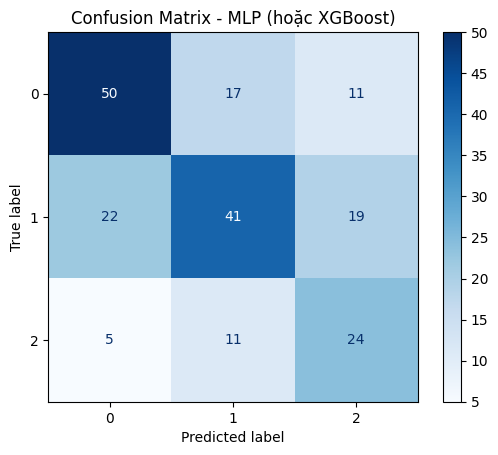

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt


cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1,2])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - MLP (hoặc XGBoost)")
plt.show()


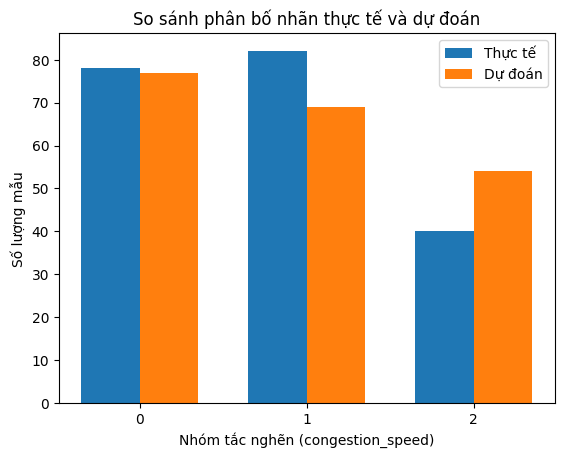

In [12]:
import numpy as np

labels = [0, 1, 2]
actual_counts = np.bincount(y_test)
pred_counts = np.bincount(y_pred)

x = np.arange(len(labels))
width = 0.35

plt.bar(x - width/2, actual_counts, width, label='Thực tế')
plt.bar(x + width/2, pred_counts, width, label='Dự đoán')
plt.xlabel("Nhóm tắc nghẽn (congestion_speed)")
plt.ylabel("Số lượng mẫu")
plt.title("So sánh phân bố nhãn thực tế và dự đoán")
plt.xticks(x, labels)
plt.legend()
plt.show()
